# Assignment 2 - Question 2: Gradient Descent, Momentum and RMSProp

This notebook answers Question 2(a)–(b). It implements each optimizer directly with NumPy and compares their losses and optimization paths for

$$J(w_1,w_2)=w_1^2+10w_2^2, \qquad \nabla J(w_1,w_2)=\begin{bmatrix}2w_1\\20w_2\end{bmatrix}.$$

No optimization library is used to perform the iterations.

## Setup

Run the cells from top to bottom in Google Colab. NumPy and Matplotlib are available in the standard Colab Python runtime.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

np.set_printoptions(precision=10, suppress=True)

## (a) Implement the optimizers

Each routine stores a copy of the initial point and a copy after each update, so the returned list contains `num_iters + 1` points. Gradients are obtained only through the supplied `grad_fn`.

- **Vanilla GD:** $w_{t+1}=w_t-\alpha\nabla J(w_t)$.
- **Momentum:** $v_0=0$, $v_{t+1}=\beta v_t+\nabla J(w_t)$, then $w_{t+1}=w_t-\alpha v_{t+1}$.
- **RMSProp:** $s_0=0$, $s_{t+1}=\rho s_t+(1-\rho)(\nabla J(w_t)\odot\nabla J(w_t))$, then $w_{t+1}=w_t-\alpha\nabla J(w_t)/(\sqrt{s_{t+1}}+\epsilon)$. RMSProp's square, square root, and division are element-wise.

In [2]:
def _prepare_optimizer_inputs(grad_fn, w0, num_iters):
    if not callable(grad_fn):
        raise TypeError("grad_fn must be callable.")
    w = np.asarray(w0, dtype=float)
    if w.ndim != 1 or w.size == 0:
        raise ValueError("w0 must be a non-empty one-dimensional array.")
    if not np.all(np.isfinite(w)):
        raise ValueError("w0 must contain only finite values.")
    if (isinstance(num_iters, (bool, np.bool_))
            or not isinstance(num_iters, (int, np.integer))
            or num_iters < 0):
        raise ValueError("num_iters must be a non-negative integer.")
    return w.copy()


def _gradient(grad_fn, w):
    gradient = np.asarray(grad_fn(w.copy()), dtype=float)
    if gradient.shape != w.shape:
        raise ValueError("grad_fn must return a gradient with the same shape as w.")
    if not np.all(np.isfinite(gradient)):
        raise FloatingPointError("grad_fn returned a non-finite gradient.")
    return gradient


def _validate_learning_rate(alpha):
    if not np.isfinite(alpha) or alpha <= 0:
        raise ValueError("alpha must be positive and finite.")


def vanilla_gd(grad_fn, w0, alpha, num_iters):
    """Run vanilla gradient descent and return the initial point and all updates."""
    w = _prepare_optimizer_inputs(grad_fn, w0, num_iters)
    _validate_learning_rate(alpha)
    iterates = [w.copy()]

    for _ in range(num_iters):
        gradient = _gradient(grad_fn, w)
        w = w - alpha * gradient
        if not np.all(np.isfinite(w)):
            raise FloatingPointError("The vanilla GD update produced a non-finite iterate.")
        iterates.append(w.copy())

    return iterates


def momentum_gd(grad_fn, w0, alpha, beta, num_iters):
    """Run momentum gradient descent and return the initial point and all updates."""
    w = _prepare_optimizer_inputs(grad_fn, w0, num_iters)
    _validate_learning_rate(alpha)
    if not np.isfinite(beta) or not 0.0 <= beta < 1.0:
        raise ValueError("beta must be finite and satisfy 0 <= beta < 1.")

    velocity = np.zeros_like(w)
    iterates = [w.copy()]

    for _ in range(num_iters):
        gradient = _gradient(grad_fn, w)
        velocity = beta * velocity + gradient
        w = w - alpha * velocity
        if not np.all(np.isfinite(w)):
            raise FloatingPointError("The momentum update produced a non-finite iterate.")
        iterates.append(w.copy())

    return iterates


def rmsprop_gd(grad_fn, w0, alpha, rho, epsilon, num_iters):
    """Run RMSProp and return the initial point and all updates."""
    w = _prepare_optimizer_inputs(grad_fn, w0, num_iters)
    _validate_learning_rate(alpha)
    if not np.isfinite(rho) or not 0.0 <= rho < 1.0:
        raise ValueError("rho must be finite and satisfy 0 <= rho < 1.")
    if not np.isfinite(epsilon) or epsilon <= 0.0:
        raise ValueError("epsilon must be positive and finite.")

    squared_gradient_average = np.zeros_like(w)
    iterates = [w.copy()]

    for _ in range(num_iters):
        gradient = _gradient(grad_fn, w)
        squared_gradient_average = (
            rho * squared_gradient_average + (1.0 - rho) * (gradient * gradient)
        )
        w = w - alpha * gradient / (np.sqrt(squared_gradient_average) + epsilon)
        if not np.all(np.isfinite(w)):
            raise FloatingPointError("The RMSProp update produced a non-finite iterate.")
        iterates.append(w.copy())

    return iterates

## (b) Run and compare the optimizers

For all three methods use $w_0=[3,1]^T$, $\alpha=0.05$, and 50 updates. The selected parameters are $\beta=0.9$ for Momentum and $\rho=0.9$, $\epsilon=10^{-8}$ for RMSProp.

In [3]:
def grad_fn(w):
    """Gradient of J(w1, w2) = w1^2 + 10*w2^2."""
    return np.array([2.0 * w[0], 20.0 * w[1]])


def objective(w):
    return w[0] ** 2 + 10.0 * w[1] ** 2


w0 = np.array([3.0, 1.0])
alpha = 0.05
num_iters = 50
beta = 0.9
rho = 0.9
epsilon = 1e-8

vanilla_iterates = vanilla_gd(grad_fn, w0, alpha, num_iters)
momentum_iterates = momentum_gd(grad_fn, w0, alpha, beta, num_iters)
rmsprop_iterates = rmsprop_gd(grad_fn, w0, alpha, rho, epsilon, num_iters)

paths = {
    "Vanilla GD": np.asarray(vanilla_iterates),
    "Momentum": np.asarray(momentum_iterates),
    "RMSProp": np.asarray(rmsprop_iterates),
}
losses = {
    name: np.array([objective(point) for point in path])
    for name, path in paths.items()
}

for name, path in paths.items():
    assert len(path) == num_iters + 1
    print(f"{name}: {len(path)} points, including w_0")
    print(f"  initial point: {path[0]}")
    print(f"  final point:   {path[-1]}")
    print(f"  initial loss:  {losses[name][0]:.12g}")
    print(f"  final loss:    {losses[name][-1]:.12g}")

Vanilla GD: 51 points, including w_0
  initial point: [3. 1.]
  final point:   [0.0154613256 0.          ]
  initial loss:  19
  final loss:    0.000239052589988
Momentum: 51 points, including w_0
  initial point: [3. 1.]
  final point:   [-0.2000407167 -0.0496523522]
  initial loss:  19
  final loss:    0.0646698491083
RMSProp: 51 points, including w_0
  initial point: [3. 1.]
  final point:   [0.5690895958 0.0000000019]
  initial loss:  19
  final loss:    0.323862968054


### Loss versus iteration

The vertical axis is logarithmic. If a computed loss is zero, the display-only values are floored at the smallest positive normal floating-point number so the plot does not take $\log(0)$. This floor is used only for plotting; the `losses` arrays retain the actual objective values.

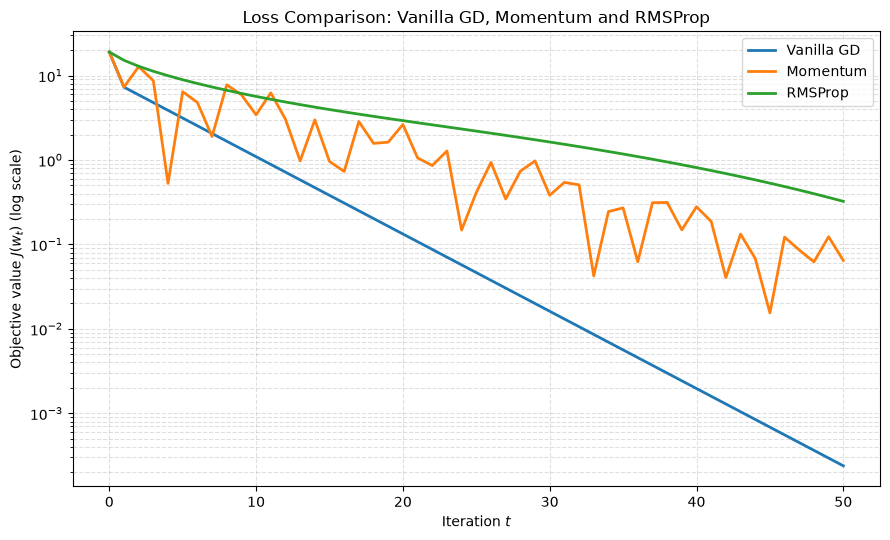

Vanilla GD: exact numerical zeros at iterations []
Momentum: exact numerical zeros at iterations []
RMSProp: exact numerical zeros at iterations []


In [4]:
iterations = np.arange(num_iters + 1)
display_floor = np.finfo(float).tiny
colors = {"Vanilla GD": "tab:blue", "Momentum": "tab:orange", "RMSProp": "tab:green"}

fig, ax = plt.subplots(figsize=(9, 5.5))
for name, values in losses.items():
    plotted_values = np.maximum(values, display_floor)
    ax.semilogy(iterations, plotted_values, linewidth=2, color=colors[name], label=name)

ax.set_xlabel("Iteration $t$")
ax.set_ylabel("Objective value $J(w_t)$ (log scale)")
ax.set_title("Loss Comparison: Vanilla GD, Momentum and RMSProp")
ax.legend()
ax.grid(True, which="both", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

for name, values in losses.items():
    zero_iterations = np.flatnonzero(values == 0.0)
    print(f"{name}: exact numerical zeros at iterations {zero_iterations.tolist()}")

### Optimization paths over common contours

Each panel shows the same objective contours with matching contour levels and identical axis limits, so the trajectories can be compared directly. The star marks the common initial point.

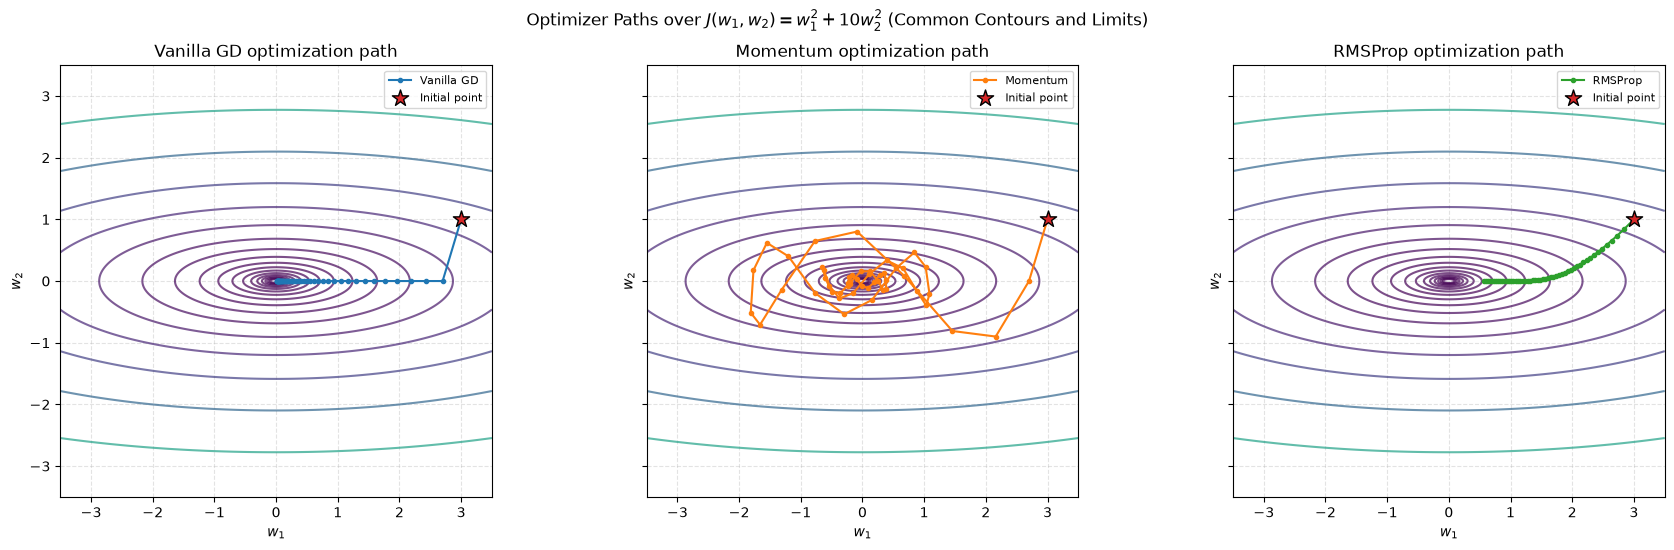

Shared axis limits: (-3.5, 3.5)
Shared contour levels: [  0.01    0.017   0.031   0.054   0.094   0.164   0.287   0.502   0.878
   1.535   2.686   4.699   8.222  14.384  25.165  44.025  77.022 134.75 ]


In [5]:
all_points = np.concatenate(list(paths.values()), axis=0)
axis_extent = max(3.5, 1.08 * float(np.max(np.abs(all_points))))
axis_limits = (-axis_extent, axis_extent)

coordinate_values = np.linspace(axis_limits[0], axis_limits[1], 350)
W1, W2 = np.meshgrid(coordinate_values, coordinate_values)
J_grid = W1**2 + 10.0 * W2**2
contour_levels = np.geomspace(0.01, float(np.max(J_grid)), 18)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharex=True, sharey=True)
for ax, (name, path) in zip(axes, paths.items()):
    ax.contour(W1, W2, J_grid, levels=contour_levels, cmap="viridis", alpha=0.7)
    ax.plot(path[:, 0], path[:, 1], "-o", color=colors[name], linewidth=1.5,
            markersize=3, label=name, zorder=3)
    ax.scatter(*path[0], marker="*", s=150, color="tab:red", edgecolor="black",
               label="Initial point", zorder=4)
    ax.set_title(f"{name} optimization path")
    ax.set_xlabel("$w_1$")
    ax.set_ylabel("$w_2$")
    ax.set_xlim(axis_limits)
    ax.set_ylim(axis_limits)
    ax.set_aspect("equal", adjustable="box")
    ax.grid(True, linestyle="--", alpha=0.35)
    ax.legend(loc="upper right", fontsize=8)
fig.suptitle("Optimizer Paths over $J(w_1,w_2)=w_1^2+10w_2^2$ (Common Contours and Limits)")
plt.tight_layout()
plt.show()

print(f"Shared axis limits: {axis_limits}")
print(f"Shared contour levels: {np.array2string(contour_levels, precision=3)}")

## Exporting for submission

1. Run every cell in Colab and save the notebook so its code, results, and figures are included.
2. Download it using **File → Download → Download .ipynb**.
3. Convert the downloaded notebook to HTML in a Python/Jupyter environment with `jupyter nbconvert --to html assignment-2-question-2.ipynb`.
4. Open the generated HTML file in a browser and use **Print → Save as PDF**. Check page breaks and confirm the code output and plots are readable before submitting.